# Módulo 7 · Python con asistencia de IA, estadística y regresión

**Guía para estudiantes.**

En esta clase nadie escribe código desde cero: se **pide** al asistente, se **lee** lo que generó, se **ejecuta** y se **verifica**.

| Bloque | Producto |
|---|---|
| 1. Entorno | Los datos cargados de dos formas |
| 2. Estadística descriptiva | Tabla resumen de las variables |
| 3. Visualización | Una figura lista para publicar |
| 4. Regresión, sobreajuste y métricas | Ajuste lineal, ajuste de curvas y gráfico de error por grado del polinomio |
| Cierre | Elección justificada de un modelo |

**Cómo trabajar con este cuaderno**

- Cada bloque empieza con un **ejemplo resuelto**. Después vienen las **consignas**: dicen qué se espera, no cómo pedirlo. El prompt lo escribís vos.
- Si te trabás, abrí la pista **¿Te trabaste?** que hay debajo de cada consigna.
- Anotá el prompt que usaste en el espacio **Tu prompt**: sirve para revisar después qué funcionó.
- Las consignas de **verificación** piden comprobar un resultado antes de seguir. No las saltees.

## Sobre los datos

Trabajamos con **DNase**: la calibración de un ensayo ELISA para la proteína DNasa recombinante en suero de rata. Son 176 mediciones de densidad óptica, de 11 corridas del ensayo, con 8 concentraciones patrón medidas por duplicado en cada una.

**Cómo funciona un ELISA.** Es un inmunoensayo: un anticuerpo fijado al fondo de un pocillo captura la proteína que se quiere medir (el *analito*). En el formato más común, un segundo anticuerpo unido a una enzima se pega al analito capturado; al agregar un sustrato, la enzima produce un compuesto coloreado. Cuanto más analito hay, más color, y el color se mide como **densidad óptica** (una absorbancia) en un lector de placas. La documentación no detalla el formato exacto de este ensayo.

Para medir una muestra desconocida, primero se construye una **curva de calibración** con patrones de concentración conocida. Eso es lo que contiene este conjunto de datos.

**Cómo están organizados los datos.**

- **Corrida:** una ejecución completa del ensayo, en la que se vuelve a medir toda la serie de patrones. Las 11 corridas tienen **las mismas 8 concentraciones** (de 0,049 a 12,5), cada una medida **por duplicado**: 16 lecturas por corrida, 176 en total.
- Los números de corrida son **etiquetas**, no un orden cronológico. La documentación no dice qué cambió entre una corrida y otra (día, placa, operador o lote de reactivos).
- Hay dos fuentes de variabilidad: entre los duplicados de una misma corrida (**repetibilidad**) y entre corridas distintas (variabilidad **entre ensayos**).
- **Unidades:** la documentación no indica la unidad de concentración; por eso hablamos de "unidades del ensayo". La densidad óptica es adimensional.

**Más información.**

- **Documentación oficial del conjunto:** [DNase en la referencia de R](https://search.r-project.org/R/refmans/datasets/html/DNase.html)
- **Archivo CSV y su página:** [DNase en Rdatasets](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/DNase.html)
- **Fuente original:** Davidian, M. y Giltinan, D. M. (1995). *Nonlinear Models for Repeated Measurement Data*. Chapman & Hall, sección 5.2.4.
- **Descripción detallada, licencia y datos simulados:** [`data/README.md`](../data/README.md) en la carpeta del curso.

## 0. Configuración

Esta es la **única celda** que nombra al conjunto de datos. El resto del cuaderno usa nombres genéricos (`datos`, `x`, `y`). Para trabajar con otros datos, se edita esta celda y se vuelve a ejecutar todo.

In [1]:
# === Configuración del conjunto de datos ===

# De dónde salen los datos (el mismo archivo en dos lugares)
RUTA_CSV = "../data/dnase.csv"  # copia del archivo en la carpeta del curso
URL_DATOS = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/DNase.csv"  # original publicado en internet
COLUMNAS_A_DESCARTAR = ["rownames"]  # columnas que no son datos
# Copia de los datos con lecturas anómalas simuladas (bloque 2).
RUTA_ANOMALIAS = "../data/dnase_con_anomalias.csv"

# Qué papel cumple cada columna
COLUMNA_X = "conc"        # variable de entrada: concentración conocida del patrón
COLUMNA_Y = "density"     # variable objetivo: densidad óptica medida
COLUMNA_GRUPO = "Run"     # variable categórica: corrida del ensayo

# Nombres para mostrar en tablas y gráficos
NOMBRE_X = "Concentración de DNasa (unidades del ensayo)"
NOMBRE_Y = "Densidad óptica"
NOMBRE_GRUPO = "Corrida"

# Bloque 2
UMBRAL_DUPLICADOS = 0.2  # diferencia máxima aceptable entre las dos lecturas duplicadas

# Bloque 4
GRUPO_CALIBRACION = 1   # corrida que se usa como curva de calibración
X_MAX_LINEAL = 1.6      # límite superior del tramo lineal de la calibración
DENSIDAD_MUESTRA = 0.30 # densidad óptica de una muestra de concentración desconocida
N_SIMULADOS = 18        # puntos del conjunto simulado para el sobreajuste
GRADO_MAXIMO = 10       # grado máximo del polinomio en el bloque de sobreajuste

SEMILLA = 32            # semilla fija: los resultados se repiten en cada ejecución

In [2]:
# Librerías que usa el cuaderno (con sus versiones en requirements.txt)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

## Bloque 1 · Entorno: VS Code, OpenCode y carga de datos

**Producto:** los datos cargados de dos formas y un error depurado.

Abrí la carpeta del curso en VS Code, abrí este cuaderno y elegí como *kernel* el entorno de Python del curso. El asistente de IA es OpenCode: a él le vas a pedir el código de cada consigna.

**Ejemplo resuelto.** Carga del archivo CSV que está en la carpeta `data` del curso. Ejecutá la celda y pedile al asistente que te explique, línea por línea, qué hace.

In [3]:
# Carga desde un archivo CSV de la carpeta del curso
datos = pd.read_csv(RUTA_CSV).drop(columns=COLUMNAS_A_DESCARTAR)
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (176, 3)


,Run,conc,density
0,1,0.048828,0.017
1,1,0.048828,0.018
2,1,0.195312,0.121
3,1,0.195312,0.124
4,1,0.390625,0.206


#### Consigna 1.1 · Carga desde una URL

El mismo archivo está publicado en internet, en la dirección `URL_DATOS`. Cargalo en un DataFrame nuevo.

**Se espera:** una tabla con las mismas filas y columnas que `datos`, sin la columna `rownames`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

pandas puede leer un CSV directamente desde una dirección web, con la misma función del ejemplo. Fijate qué hace el ejemplo con `COLUMNAS_A_DESCARTAR`.

</details>

**Tu prompt:**

*...*

In [4]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 1.2 · Verificación: ¿son la misma tabla?

Comprobá con código, no a ojo, que las dos cargas dieron exactamente la misma tabla.

**Se espera:** un resultado `True` o `False`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Que tengan la misma cantidad de filas no alcanza: pueden diferir los valores. pandas tiene una forma de comparar dos tablas completas de una vez.

</details>

**Tu prompt:**

*...*

In [5]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 1.3 · Cuando algo falla: depurar sin saber programar

Tarde o temprano, una celda va a fallar. No hace falta saber programar para resolverlo, pero sí leer el mensaje de error y saber qué preguntarle al asistente. La celda siguiente falla: ejecutala y, antes de pedir ayuda, mirá la última línea del mensaje.

Después pedile al asistente que te explique **qué salió mal**, **por qué** y **cómo corregirlo**, y aplicá la corrección.

**Se espera:** una celda corregida que imprima la densidad óptica media, y una frase tuya que explique el error con tus palabras.

**Antes de seguir:** ¿la corrección del asistente usa las variables de la configuración o escribe el nombre de la columna a mano? ¿Por qué importa?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La última línea de un error de Python dice el tipo de error y qué lo causó. Copiá el mensaje completo en el chat del asistente: es la mejor información que le podés dar.

</details>

In [6]:
# Esta celda falla a propósito: leé el mensaje de error
print(datos["densidad"].mean())

KeyError: 'densidad'

**Tu prompt:**

*...*

In [7]:
# Pegá o escribí aquí el código que generó el asistente


## Bloque 2 · Estadística descriptiva

**Producto:** tabla resumen de las variables.

**Ejemplo resuelto.** Tabla resumen de la variable de entrada y la variable objetivo.

In [8]:
tabla_resumen = datos[[COLUMNA_X, COLUMNA_Y]].agg(["count", "mean", "median", "std", "min", "max"]).T
tabla_resumen.columns = ["n", "media", "mediana", "desvío", "mínimo", "máximo"]
tabla_resumen.index = [NOMBRE_X, NOMBRE_Y]
tabla_resumen.round(3)

,n,media,mediana,desvío,mínimo,máximo
Concentración de DNasa (unidades del ensayo),176.0,3.107,1.172,4.060,0.049,12.500
Densidad óptica,176.0,0.719,0.526,0.596,0.011,2.003


#### Consigna 2.1 · Conteos y proporciones

Contá cuántas lecturas hay en cada corrida y qué proporción del total representa cada una.

**Se espera:** una tabla con 11 filas, una por corrida, y dos columnas: cantidad de lecturas y proporción. Las proporciones tienen que sumar 1.

**Antes de seguir:** ¿las corridas están balanceadas? ¿Qué te dice eso sobre cómo se diseñó el experimento?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Primero contá cuántas lecturas tiene cada corrida; la proporción es ese conteo dividido por el total de lecturas (176).

</details>

**Tu prompt:**

*...*

In [9]:
# Pegá o escribí aquí el código que generó el asistente


### Lecturas anómalas

En un laboratorio real, entre cientos de lecturas suele colarse alguna equivocada: un número mal tipeado, un pocillo contaminado, uno al que le faltó reactivo. Antes de analizar, hay que encontrarlas.

> ⚠️ **Datos con anomalías simuladas.** El archivo siguiente es una copia de los mismos datos en la que el equipo docente **alteró algunas lecturas** a propósito. No sabés cuántas ni cuáles: tu trabajo es encontrarlas.

> **Una regla de oro:** en ciencia no se borra un dato porque "se ve raro". Hace falta un **criterio** que se pueda explicar, y lo que se quita se **documenta**.

**Ejemplo resuelto.** Carga de los datos con anomalías.

In [10]:
datos_anomalos = pd.read_csv(RUTA_ANOMALIAS).drop(columns=COLUMNAS_A_DESCARTAR)
print("Filas y columnas:", datos_anomalos.shape)

Filas y columnas: (176, 3)


#### Consigna 2.2 · Diagnóstico visual

Mirá los datos con anomalías con dos gráficos: uno con todas las lecturas de densidad óptica juntas y otro con las lecturas de cada concentración patrón por separado (por ejemplo, un boxplot por concentración). Después listá las lecturas que te parezcan sospechosas.

**Se espera:** dos gráficos simples (el estilo no importa: eso es el bloque 3) y una tabla con las lecturas sospechosas, con su corrida, su concentración y su densidad óptica.

**Antes de seguir:** ¿Todas las lecturas sospechosas te parecen errores? Fijate de qué corridas son.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Un boxplot marca como puntos sueltos los valores que quedan lejos de la caja. Para listarlos con código, pedí la regla que usa el boxplot (1,5 veces el rango intercuartil) aplicada dentro de cada concentración. Si un solo valor aplasta la escala del gráfico, pedí limitar el eje y para ver el resto.

</details>

**Tu prompt:**

*...*

In [11]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 2.3 · Un criterio con sentido experimental

Cada lectura se hizo por duplicado: en una misma corrida, las dos lecturas de una concentración deberían coincidir casi exactamente. Para cada par de duplicados, calculá la diferencia entre sus dos lecturas y marcá los pares cuya diferencia supere `UMBRAL_DUPLICADOS`.

**Se espera:** una tabla con los pares sospechosos: corrida, concentración, las dos lecturas y su diferencia.

**Antes de seguir:** Compará con la lista de la consigna 2.2. ¿Qué lecturas sospechosas desaparecieron? ¿Por qué tiene sentido que desaparezcan?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Agrupá las lecturas por corrida y concentración: cada grupo tiene exactamente dos filas. La diferencia es el máximo menos el mínimo del grupo.

</details>

**Tu prompt:**

*...*

In [12]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 2.4 · Depurar y verificar

En cada par sospechoso, una lectura es la buena y la otra la anómala. Decidí cuál quitar comparando las dos con lo que midieron las demás corridas en esa misma concentración, y armá un DataFrame nuevo sin las lecturas anómalas. No modifiques `datos_anomalos`: así queda registro de lo que había.

**Se espera:** un DataFrame depurado, una tabla con las lecturas eliminadas (corrida, concentración, valor) y la cantidad de filas antes y después.

**Antes de seguir:** Escribí en una frase el criterio que usaste, como lo pondrías en la sección de métodos de un trabajo.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada concentración, la mediana de todas las corridas es una buena referencia. En cada par, la lectura anómala es la que queda más lejos de esa mediana.

</details>

**Tu prompt:**

*...*

In [13]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Bloque 3 · Visualización

**Producto:** una figura lista para presentar.

En este conjunto, la variable de entrada toma **8 concentraciones patrón** (de 0,049 a 12,5), y cada una se midió en **11 corridas** por duplicado: 22 lecturas por concentración.

| Gráfico | Pregunta sobre estos datos |
|---|---|
| Histograma | ¿Cómo se distribuyen las lecturas de densidad óptica? |
| Dispersión | ¿Cómo cambia la densidad óptica con la concentración? |
| Boxplot | ¿Cuánto varían las 22 lecturas de cada concentración patrón? |
| Barras | En la concentración más alta (12,5), ¿la densidad óptica media es parecida en las 11 corridas, o hay corridas que dan lecturas más altas que el resto? |

**Ejemplo resuelto.** Histograma de las lecturas de densidad óptica, con seaborn.

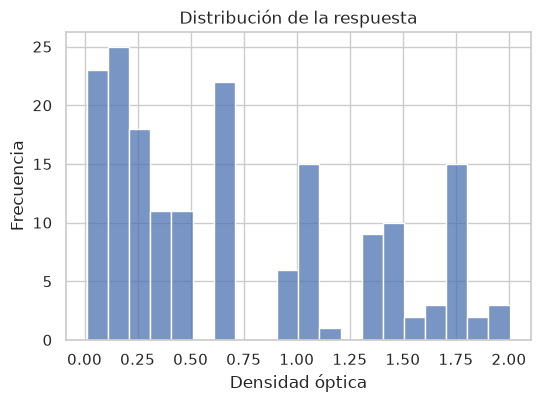

In [14]:
fig, eje = plt.subplots(figsize=(6, 4))
sns.histplot(data=datos, x=COLUMNA_Y, bins=20, ax=eje)
eje.set(title="Distribución de la respuesta", xlabel=NOMBRE_Y, ylabel="Frecuencia")
plt.show()

#### Consigna 3.1 · Tres gráficos, tres preguntas

Hacé los otros tres gráficos de la tabla:

- **Dispersión:** densidad óptica (eje y) contra concentración (eje x), con un color distinto para cada corrida.
- **Boxplot:** una caja por cada concentración patrón (8 cajas), con las 22 lecturas de esa concentración.
- **Barras:** una barra por corrida (11 barras), con su densidad óptica media en la concentración más alta (12,5).

**Se espera:** tres gráficos con título y con ejes legibles ("Concentración de DNasa", "Densidad óptica", "Corrida"), no con los nombres de las columnas (`conc`, `density`, `Run`).

**Antes de seguir:** ¿qué gráfico muestra mejor que algunas corridas leen más alto que otras? ¿Cuáles son?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Pedí los gráficos de a uno. Para las barras, primero quedate solo con las filas de concentración 12,5.

</details>

**Tu prompt:**

*...*

In [15]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 3.2 · Una figura para publicar

Hacé un gráfico de la densidad óptica media en cada concentración patrón (el promedio de sus 22 lecturas), con barras de error de un desvío estándar y las lecturas individuales de fondo.

Después elegí una revista de tu área y pedile al asistente que adapte la figura a sus normas para autores: tamaño (una o dos columnas), tipografía y tamaño de letra, grosor de líneas, resolución y formato del archivo. Guardá la figura en un archivo.

**Se espera:** la figura guardada en un archivo y una tabla corta con tres requisitos de la revista: qué dice la guía para autores, qué hizo el asistente y si coincide.

**Antes de seguir:** el asistente puede afirmar con seguridad normas que no son las reales. ¿Cuántos de los tres requisitos coincidieron con la guía oficial?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá la guía para autores en la página de la revista (suele llamarse *Author Guidelines* o *Guide for Authors*) y buscá la sección de figuras o *artwork*. Las concentraciones siguen una dilución seriada: ¿qué escala del eje x las separa mejor?

</details>

**Tu prompt:**

*...*

In [16]:
# Pegá o escribí aquí el código que generó el asistente


**Tu prompt:**

*...*

In [17]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 3.3 · Verificación: el gráfico contra la tabla

Elegí una concentración patrón en el boxplot y leé a ojo la mediana de su caja (la línea del medio). Comparala con el valor que imprime la celda siguiente.

**Se espera:** que tu lectura y el valor de la tabla difieran en menos de 0,05.

In [18]:
print(datos.groupby(COLUMNA_X)[COLUMNA_Y].median().round(3).to_string())

conc
0.048828     0.051
0.195312     0.154
0.390625     0.240
0.781250     0.406
1.562500     0.674
3.125000     1.042
6.250000     1.409
12.500000    1.739


## Bloque 4 · Regresión, sobreajuste y métricas

**Producto:** ajuste lineal, ajuste de curvas y gráfico de error por grado del polinomio.

Retomamos la pregunta de la teoría: **¿un modelo que se ajusta mejor a los datos que ya tenemos es un modelo mejor?**

### 4.1 Regresión lineal simple: curva de calibración

Usamos una sola corrida y solo el tramo bajo de concentraciones, donde la respuesta es aproximadamente lineal.

> **Una simplificación.** La ley de Beer-Lambert vale para el producto coloreado dentro del pocillo: su absorbancia es proporcional a su concentración. Pero en un ELISA la relación entre la concentración del **analito** y la densidad óptica no es lineal, porque los sitios de unión del anticuerpo se saturan. Solo es aproximadamente lineal en el tramo bajo. En el laboratorio, la calibración de un ELISA se ajusta con una logística de cuatro parámetros (la vemos en el paso 4.2); aquí usamos el tramo lineal para aprender a leer pendiente, ordenada y R².

**Ejemplo resuelto.** Selección de los datos de calibración: una corrida y el tramo lineal.

In [19]:
calibracion = datos[(datos[COLUMNA_GRUPO] == GRUPO_CALIBRACION) & (datos[COLUMNA_X] <= X_MAX_LINEAL)]
x_cal = calibracion[[COLUMNA_X]].to_numpy()
y_cal = calibracion[COLUMNA_Y].to_numpy()
print(f"Puntos de calibración: {len(calibracion)}")

Puntos de calibración: 10


#### Consigna 4.1 · La recta de calibración

Ajustá una regresión lineal de `y_cal` contra `x_cal` y graficá los puntos con la recta.

**Se espera:** la pendiente, la ordenada al origen y el R² impresos con cuatro decimales, cada uno con sus unidades, y un gráfico con la ecuación de la recta en la leyenda.

**Antes de seguir:** ¿En qué unidades está la pendiente? ¿Qué significa, físicamente, la ordenada al origen?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene un modelo de regresión lineal. La pendiente y la ordenada quedan guardadas dentro del modelo después de ajustarlo.

</details>

**Tu prompt:**

*...*

In [20]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.2 · ¿Cómo predecir? La concentración de una muestra desconocida

Una curva de calibración se ajusta en un sentido y se usa en el otro: se ajusta la densidad óptica en función de la concentración, pero en el laboratorio se mide la densidad óptica de una muestra y se quiere saber su concentración.

Una muestra de concentración desconocida dio una densidad óptica de **0,30** (`DENSIDAD_MUESTRA`). Despejá x de la recta y calculá **a mano** su concentración. Después pedí que se calcule con código y que se marque la muestra en el gráfico de la calibración.

**Se espera:** la concentración calculada a mano y con código, que tienen que coincidir, y el gráfico con la muestra marcada sobre la recta.

**Antes de seguir:** ¿qué harías si la muestra hubiera dado una densidad óptica de 1,5? ¿Se puede usar esta recta?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Si y = pendiente · x + ordenada, ¿cuánto vale x?

</details>

**Tu prompt:**

*...*

In [21]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

### 4.2 Ajuste de curvas

Ahora usamos el **rango completo** de concentraciones de la misma corrida. La respuesta se curva y se satura. Vamos a comparar tres tipos de modelo:

1. una recta;
2. polinomios de grado 2 y 3;
3. una función con sentido físico: la **logística de cuatro parámetros**, el modelo estándar de los inmunoensayos. Describe una respuesta que parte de un mínimo, crece y se satura cuando se ocupan todos los sitios de unión.

$$y = A + \frac{B - A}{1 + e^{(x_{medio} - \ln x)/escala}}$$

**¿Por qué una S?** Los anticuerpos del pocillo tienen una cantidad limitada de sitios de unión. Con muy poco analito, la señal apenas se separa del fondo; en la zona media, cada aumento de concentración ocupa más sitios y la señal crece rápido; con mucho analito, los sitios están casi todos ocupados y la señal se satura. Graficada contra el **logaritmo** de la concentración, esa respuesta tiene forma de S.

**Qué representa cada parámetro en el experimento:**

| Parámetro | En la curva | En el ensayo |
|---|---|---|
| **A** | asíntota inferior | señal sin analito: el fondo o blanco |
| **B** | asíntota superior | señal con todos los sitios ocupados: la saturación |
| **x_medio** | punto de inflexión, en ln(x) | ln de la concentración que da la mitad de la respuesta entre A y B. Su exponencial es la **EC50**, una medida de la sensibilidad del ensayo |
| **escala** | qué tan empinada es la S | cuanto más chica, más abrupto el paso del fondo a la saturación y más angosto el rango útil de medición |

La zona útil para medir muestras es la parte central de la S: allí un cambio de concentración produce un cambio claro de señal. Cerca de las mesetas, la señal casi no cambia y la concentración queda mal determinada.

**Ejemplo resuelto.** Los datos de la corrida completa y dos funciones que vamos a usar: la logística y el RMSE.

In [22]:
corrida = datos[datos[COLUMNA_GRUPO] == GRUPO_CALIBRACION]
x_c = corrida[COLUMNA_X].to_numpy()
y_c = corrida[COLUMNA_Y].to_numpy()

def logistica_4p(x, A, B, x_medio, escala):
    """Logística de cuatro parámetros en función de ln(x)."""
    return A + (B - A) / (1 + np.exp((x_medio - np.log(x)) / escala))

def rmse(y_real, y_predicho):
    """Raíz del error cuadrático medio, en las unidades de y."""
    return np.sqrt(mean_squared_error(y_real, y_predicho))

**Ejemplo resuelto.** Una logística con valores **ilustrativos** (no ajustados a los datos) para ver qué controla cada parámetro. Pedile al asistente que cambie uno de los valores y observá cómo se mueve la curva.

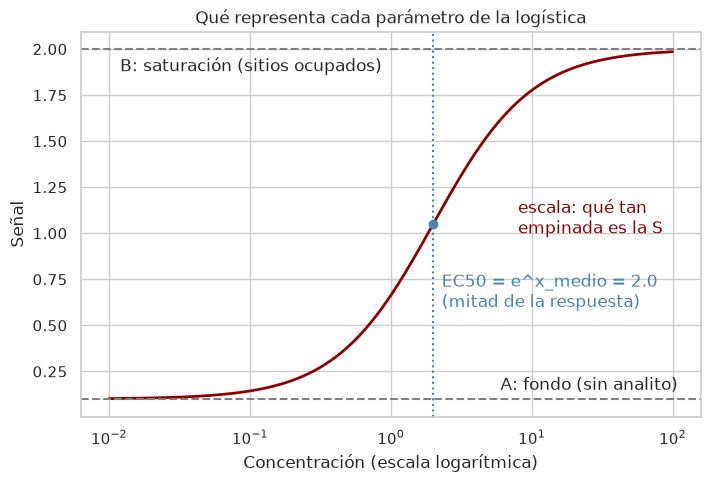

In [23]:
# Valores ilustrativos, elegidos para que se vea cada parámetro (no son un ajuste)
A, B, x_medio, escala = 0.1, 2.0, np.log(2.0), 0.8
ec50 = np.exp(x_medio)

x_ilustracion = np.geomspace(0.01, 100, 300)
fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(x_ilustracion, logistica_4p(x_ilustracion, A, B, x_medio, escala), color="darkred", linewidth=2)
eje.axhline(A, color="gray", linestyle="--")
eje.axhline(B, color="gray", linestyle="--")
eje.axvline(ec50, color="steelblue", linestyle=":")
eje.plot(ec50, (A + B) / 2, "o", color="steelblue")

eje.text(6, A + 0.05, "A: fondo (sin analito)")
eje.text(0.012, B - 0.12, "B: saturación (sitios ocupados)")
eje.text(ec50 * 1.15, 0.6, f"EC50 = e^x_medio = {ec50:.1f}\n(mitad de la respuesta)", color="steelblue")
eje.text(8, 1.0, "escala: qué tan\nempinada es la S", color="darkred")

eje.set_xscale("log")
eje.set(xlabel="Concentración (escala logarítmica)", ylabel="Señal", title="Qué representa cada parámetro de la logística")
plt.show()


#### Consigna 4.3 · Cuatro modelos para la misma curva

Ajustá a `x_c` e `y_c` una recta, un polinomio de grado 2, uno de grado 3 y la función `logistica_4p`. Compará los cuatro.

**Se espera:** una tabla con el RMSE de cada modelo y un gráfico con las mediciones y las cuatro curvas. Imprimí los cuatro parámetros ajustados de la logística.

**Antes de seguir:** ¿El modelo con menor RMSE es necesariamente el mejor? Mirá la forma de cada curva entre los puntos.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los polinomios se ajustan con numpy. Para la logística hace falta `curve_fit` de scipy, que necesita valores iniciales razonables: A cerca de la respuesta mínima, B cerca de la máxima, x_medio cerca del logaritmo de una concentración intermedia y escala cerca de 1.

</details>

**Tu prompt:**

*...*

In [24]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.4 · Verificación: ¿los parámetros tienen sentido?

Los parámetros de la logística tienen significado: **A** es la respuesta sin analito (el blanco) y **B** es la meseta a concentración muy alta. Compará A con la respuesta medida en la concentración más baja, y B con la respuesta más alta medida.

**Se espera:** que A se parezca a la lectura del patrón más bajo y que B sea mayor que la lectura más alta. Mirando el gráfico, decidí si la curva llegó a la meseta dentro del rango medido.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los parámetros quedaron guardados en el orden A, B, x_medio, escala.

</details>

**Tu prompt:**

*...*

In [25]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

### 4.3 Sobreajuste

> ⚠️ **Datos simulados.** Las mediciones reales de cada corrida tienen solo 8 concentraciones distintas, medidas por duplicado. Con tan pocos valores distintos de x no se puede mostrar bien el sobreajuste. Por eso **simulamos** un conjunto de 18 puntos:
>
> - la curva "verdadera" es la logística de cuatro parámetros ajustada a **todas** las corridas reales;
> - el ruido es gaussiano, con el desvío de los residuos de ese mismo ajuste (es decir, la variabilidad real entre corridas).
>
> Así, la forma y el ruido salen de los datos, pero los puntos no son mediciones.
>
> **Otra simplificación:** el ruido simulado es igual en toda la curva. En los datos reales, el desvío entre corridas crece con la concentración: es de 0,024 a 0,031 en los cinco patrones más bajos y sube a 0,069 y 0,085 en los dos más altos. Por eso, en la práctica, los ajustes de ELISA suelen dar menos peso a los puntos más ruidosos (regresión ponderada). Aquí no lo hacemos, para concentrarnos en el sobreajuste.

**Ejemplo resuelto.** Generación del conjunto simulado. Ejecutala y leé los comentarios.

In [26]:
# Curva verdadera y ruido, estimados con todas las corridas reales
x_todas = datos[COLUMNA_X].to_numpy()
y_todas = datos[COLUMNA_Y].to_numpy()
parametros_verdaderos, _ = curve_fit(logistica_4p, x_todas, y_todas, p0=[0, y_todas.max(), np.log(np.median(x_todas)), 1])
residuos = y_todas - logistica_4p(x_todas, *parametros_verdaderos)
desvio_ruido = residuos.std(ddof=len(parametros_verdaderos))

# Conjunto simulado: concentraciones espaciadas en escala logarítmica, como en una dilución seriada
generador = np.random.default_rng(SEMILLA)
x_sim = np.geomspace(x_todas.min(), x_todas.max(), N_SIMULADOS)
y_sim = logistica_4p(x_sim, *parametros_verdaderos) + generador.normal(0, desvio_ruido, N_SIMULADOS)

print(f"Desvío del ruido (de los residuos reales): {desvio_ruido:.4f}")
print(f"Puntos simulados: {N_SIMULADOS}")

Desvío del ruido (de los residuos reales): 0.0461
Puntos simulados: 18


#### Consigna 4.5 · Error de entrenamiento y de prueba por grado

Dividí los datos simulados en entrenamiento (70 %) y prueba (30 %) usando `SEMILLA`. Para cada grado de polinomio entre 1 y `GRADO_MAXIMO`, ajustá el modelo con los datos de entrenamiento y calculá el RMSE en los dos conjuntos. Trabajá con **ln(x_sim)** como variable de entrada: las concentraciones siguen una dilución seriada y en escala lineal quedarían amontonadas cerca de cero.

**Se espera:** una tabla con el RMSE de entrenamiento y de prueba para cada grado, y un gráfico de ambos contra el grado, con el eje y en escala logarítmica y una línea horizontal en `desvio_ruido`.

**Antes de seguir:** ¿Qué le pasa al error de entrenamiento a medida que sube el grado? ¿Y al de prueba?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene una función para dividir datos en entrenamiento y prueba, y otra para generar las potencias de x. Con grados altos conviene estandarizar x antes de elevarla a potencias; se pueden encadenar los pasos en un *pipeline*.

</details>

**Tu prompt:**

*...*

In [27]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.6 · Verificación: ¿dónde empieza el sobreajuste?

Mirando **solo el gráfico**, anotá el grado a partir del cual el error de prueba empeora. Después pedí que se calcule a partir de la tabla.

**Se espera:** tu lectura del gráfico y el grado con menor RMSE de prueba según la tabla. Si no coinciden, explicá por qué.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá el grado donde la curva de prueba tiene su mínimo; pandas tiene una función que devuelve la posición del mínimo de una columna.

</details>

**Tu prompt:**

*...*

In [28]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.7 · Ver el sobreajuste

Dibujá sobre los datos simulados dos polinomios ajustados con los datos de entrenamiento: el de mejor grado y el de `GRADO_MAXIMO`. Distinguí los puntos de entrenamiento de los de prueba.

**Se espera:** un gráfico con eje x en escala logarítmica donde se vea cómo el polinomio de grado alto pasa por los puntos de entrenamiento pero se aleja de los de prueba.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los modelos se ajustaron con ln(x): para dibujarlos, generá muchos valores de ln(x) entre el mínimo y el máximo y volvé a la concentración con `np.exp`. Limitá el eje y para que las oscilaciones no aplasten el gráfico.

</details>

**Tu prompt:**

*...*

In [29]:
# Pegá o escribí aquí el código que generó el asistente


**Para explorar:** cambiá `SEMILLA` en la configuración y volvé a ejecutar. ¿Cambia el grado óptimo? ¿Por qué podría cambiar con tan pocos puntos?

### 4.4 Métricas

Tres preguntas:

1. ¿Por qué el R² sobre los datos de **entrenamiento** engaña?
2. ¿Qué significa el RMSE en las unidades de la variable medida?
3. ¿En qué se diferencian el RMSE y el MAE?

#### Consigna 4.8 · Tres métricas, dos conjuntos

Para el mejor grado y para `GRADO_MAXIMO`, calculá R², RMSE y MAE en entrenamiento y en prueba.

**Se espera:** una tabla con una fila por combinación de grado y conjunto, y una columna por métrica.

**Antes de seguir:** Compará el R² de entrenamiento y de prueba del grado máximo. ¿Qué significa un R² negativo?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las tres métricas están en `sklearn.metrics`. Reajustá cada modelo con los datos de entrenamiento y evaluá con los dos conjuntos.

</details>

**Tu prompt:**

*...*

In [30]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.9 · El error en unidades de concentración

Traducí el RMSE de prueba del mejor grado a unidades de concentración usando la pendiente de la calibración del paso 4.1.

**Se espera:** un valor en unidades de concentración y una frase que diga qué significa para quien mide una muestra.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

En el tramo lineal, un error de respuesta de tamaño RMSE equivale aproximadamente a un error de concentración de RMSE / pendiente.

</details>

**Tu prompt:**

*...*

In [31]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Cierre

**Producto:** el cuaderno completo y guardado.

#### Consigna final · Elegir y justificar un modelo

1. Pedile al asistente que explique, en lenguaje sencillo, las tablas `tabla_ajustes`, `tabla_grados` y `tabla_metricas`, y que recomiende un modelo para describir la curva de respuesta.
2. **Verificá** la explicación contra las tablas: ¿cita bien los números? ¿Usa el error de prueba, y no el de entrenamiento, para elegir?
3. Escribí tu elección y justificala en tres o cuatro frases: qué métrica usaste, sobre qué datos y qué tiene de bueno o de malo el modelo.

**Tu elección y justificación:**

*...*